# UBOS District Population Forecaster

The OOP model definitions live in `src/ubos.py`. District data, calculations, validation, planning outputs, and plotting live in `src/ubos_analysis.py`; this notebook imports and uses both.

The validation split trains on 2015–2021 and evaluates on 2022–2024. Models are selected by the lowest holdout MAPE. Mbarara and Mbale are illustrative additions to the three supplied districts.

`statistics.variance` calculates sample variance (divides by $N-1$). NumPy's `np.var` defaults to population variance (`ddof=0`, divides by $N$); `np.var(..., ddof=1)` calculates sample variance and matches `statistics.variance`.

The Fibonacci model applies ratios 3/2, 5/3, 8/5, and so on. These approach 1.618, implying implausible sustained annual growth for ordinary district population forecasting; it is included as a critical comparison, not as a planning recommendation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.ubos import (
    CAGRForecaster,
    DistrictPopulation,
    FibonacciRatioForecaster,
    Forecaster,
    LinearTrendForecaster,
)
from src.ubos_analysis import descriptive_statistics, run_analysis

In [2]:
results = run_analysis(report=False)

print('Selected models:', results['selected_models'])
print('Fastest relative growth:', results['fastest_relative_growth'])

statistics_rows = [
    {'District': district.district_name, **descriptive_statistics(district)}
    for district in results['districts']
]
statistics_table = pd.DataFrame(statistics_rows).set_index('District')
statistics_table

Selected models: {'Kampala': 'CAGRForecaster', 'Wakiso': 'CAGRForecaster', 'Gulu': 'CAGRForecaster', 'Mbarara': 'CAGRForecaster', 'Mbale': 'CAGRForecaster'}
Fastest relative growth: Wakiso


,statistics_mean,statistics_median,statistics_variance,statistics_stdev,numpy_mean,numpy_median,numpy_variance_ddof0,numpy_stdev_ddof0,numpy_variance_ddof1,numpy_stdev_ddof1
District,,,,,,,,,,
Kampala,1477.0,1460.0,42601.111111,206.400366,1477.0,1460.0,38341.00,195.808580,42601.111111,206.400366
Wakiso,1280.0,1260.0,60066.666667,245.085019,1280.0,1260.0,54060.00,232.508064,60066.666667,245.085019
Gulu,389.5,382.5,2885.833333,53.719953,389.5,382.5,2597.25,50.963222,2885.833333,53.719953
Mbarara,559.5,555.0,3463.611111,58.852452,559.5,555.0,3117.25,55.832338,3463.611111,58.852452
Mbale,608.0,600.0,4545.555556,67.420735,608.0,600.0,4091.00,63.960926,4545.555556,67.420735


In [3]:
validation_rows = [
    {'District': district, 'Model': model, **metrics}
    for district, model_scores in results['validation'].items()
    for model, metrics in model_scores.items()
]
validation_table = pd.DataFrame(validation_rows)
validation_table.sort_values(['District', 'MAPE']).reset_index(drop=True)

,District,Model,MAE,RMSE,MAPE
0,Gulu,CAGRForecaster,9.437351,10.869351,2.024973
1,Gulu,LinearTrendForecaster,18.571429,20.287056,4.009123
2,Gulu,FibonacciRatioForecaster,638.333333,753.818059,136.654883
3,Kampala,CAGRForecaster,9.619128,10.385147,0.551460
4,Kampala,LinearTrendForecaster,37.619048,38.974961,2.165173
5,Kampala,FibonacciRatioForecaster,2490.000000,2939.484082,141.466213
6,Mbale,CAGRForecaster,11.018888,12.565833,1.567812
7,Mbale,LinearTrendForecaster,21.607143,23.366033,3.089578
8,Mbale,FibonacciRatioForecaster,1003.333333,1183.703581,142.389474
9,Mbarara,CAGRForecaster,4.897216,6.072636,0.759656


In [4]:
forecast_rows = []
for district, forecast in results['forecasts'].items():
    forecast_rows.append({
        'District': district,
        'Selected model': forecast['model'],
        '2029 population (thousands)': forecast['population'][-1],
        '2029 95% interval (thousands)': (
            forecast['lower_95'][-1], forecast['upper_95'][-1]
        ),
        'Actual variance': forecast['actual_variance'],
        'Forecast variance': forecast['forecast_variance'],
        'Classrooms in 2024': forecast['classrooms_2024'],
        'Classrooms in 2029': forecast['classrooms_2029'],
        'Additional classrooms': forecast['additional_classrooms'],
    })

planning_table = pd.DataFrame(forecast_rows).set_index('District')
planning_table

,Selected model,2029 population (thousands),2029 95% interval (thousands),Actual variance,Forecast variance,Classrooms in 2024,Classrooms in 2029,Additional classrooms
District,,,,,,,,
Kampala,CAGRForecaster,2254.763430,"(2209.191393704362, 2291.8547022725165)",38341.00,17286.145828,6114,7658,1544
Wakiso,CAGRForecaster,2284.670736,"(2260.5927283237356, 2305.7975658762807)",54060.00,32105.089873,5672,7760,2088
Gulu,CAGRForecaster,601.270248,"(587.640591831263, 616.6413427202604)",2597.25,1229.237037,1631,2043,412
Mbarara,CAGRForecaster,778.469021,"(767.4955973131505, 789.4928916403661)",3117.25,1261.523256,2225,2644,419
Mbale,CAGRForecaster,862.677940,"(843.8198505244596, 884.8897363729027)",4091.00,1687.199087,2446,2930,484


## Interpreting forecast variance

The actual-series variance uses ten observed values, while the forecast-series variance uses five projected values. Both describe spread, not forecast uncertainty; the periods, lengths, and trends differ. The bootstrap interval gives a separate, approximate measure of forecast uncertainty by resampling centered in-sample residuals.

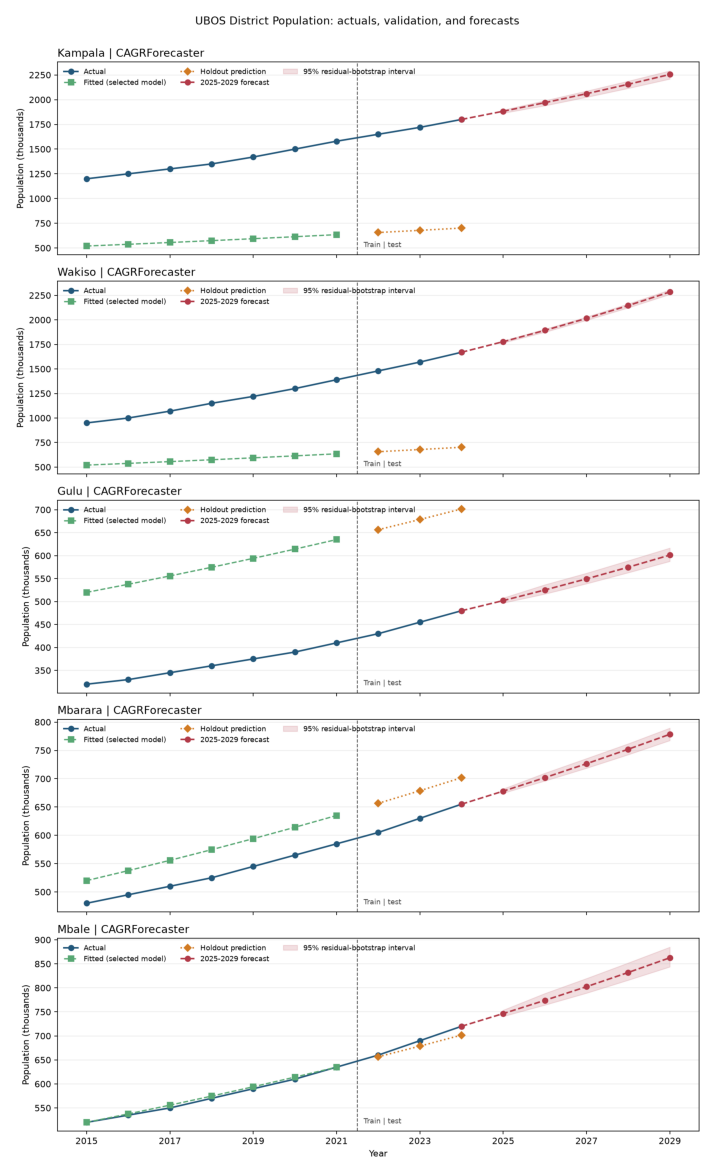

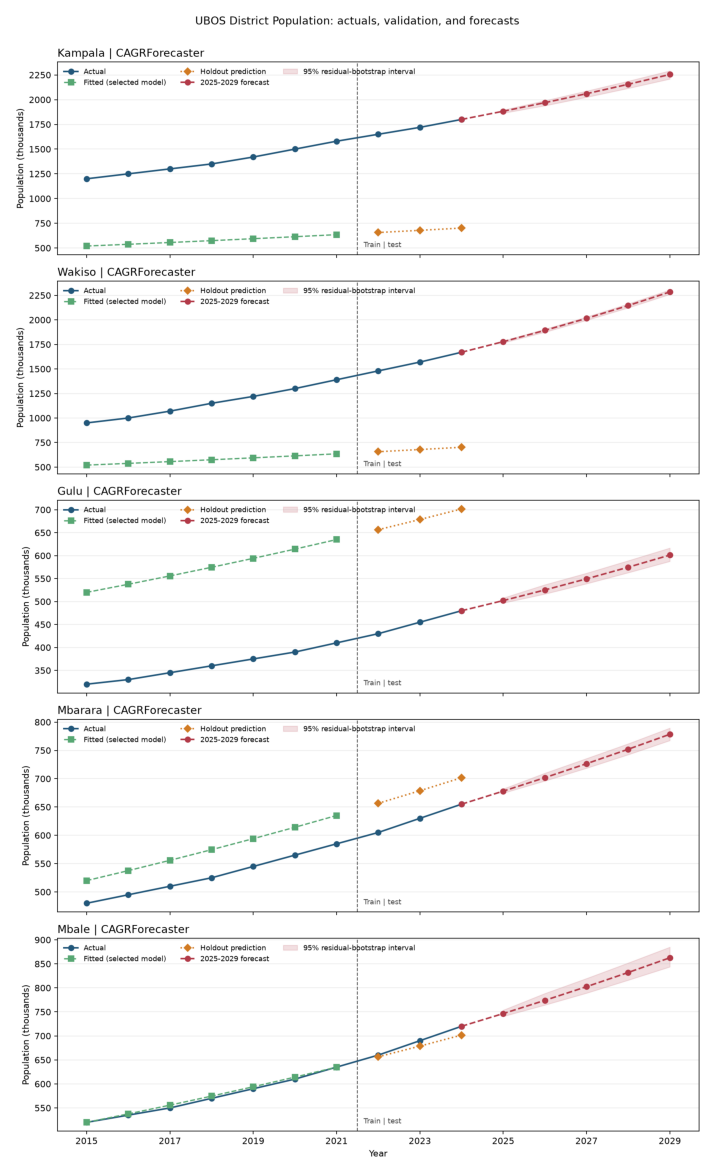

In [5]:
forecast_figure, forecast_axis = plt.subplots(figsize=(11, 15))
forecast_axis.imshow(plt.imread(results['plot_path']))
forecast_axis.axis('off')
forecast_figure